In [16]:
import sys
sys.path.insert(0, '..')

# =====================================================
# EXPLORATORY ANALYSIS: METRICS OVER TIME
# =====================================================
# This notebook analyzes how metrics changes over time
# for different player types, with 95% confidence intervals.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

# Import utility functions from plot_utilities
from shared.plot_utilities import (
    load_turn_data,
    setup_notebook_display,
    plot_metric_over_time  # Generalized function for any metric
)

# Set up notebook display and plotting style
setup_notebook_display(figsize=(12, 6))

# Load turn data with player type mapping automatically applied
turn_df = load_turn_data('../turn_data.csv', exclude_non_llm=True)

d:\Cache\Onedrive - Arizona\OneDrive - University of Arizona\Vox Deorum\nlp-2026-tiny-4player\analysis\exploratory\..\plot_utilities.py:829: DtypeWarning: Columns (71) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


✓ Loaded turn data: 1040520 rows
✓ Filters applied: exclude_non_llm=True
✓ Unique conditions: 13
✓ Unique player types: 15
✓ Turn range: 0 - 500
✓ Unique civilizations: 43

Player Type Distribution:
  Vanilla: 330664 rows (31.8%)
  GLM-4.7-Simple: 75725 rows (7.3%)
  GLM-4.7-Briefed: 75725 rows (7.3%)
  Kimi-K2.5-Simple: 71212 rows (6.8%)
  Kimi-K2.5-Briefed: 71212 rows (6.8%)
  GPT-OSS-120B-Briefed: 65948 rows (6.3%)
  GPT-OSS-120B-Simple: 65948 rows (6.3%)
  Minimax-M2.5-Simple: 50190 rows (4.8%)
  Minimax-M2.5-Briefed: 50190 rows (4.8%)
  Deepseek-3.2-Briefed: 48321 rows (4.6%)
  Deepseek-3.2-Simple: 48321 rows (4.6%)
  Qwen-3.5-Briefed: 32340 rows (3.1%)
  Qwen-3.5-Simple: 32340 rows (3.1%)
  Sonnet-4.5-Briefed: 11192 rows (1.1%)
  Sonnet-4.5-Simple: 11192 rows (1.1%)

Condition Distribution:
  2026-deepseek-v-kimi2-v-glm-standard: 281688 rows (27.1%)
  2026-oss-v-glm-standard: 223776 rows (21.5%)
  2026-qwen-v-kimi2-v-minimax-standard: 138720 rows (13.3%)
  2026-oss-v-qwen-v-minim

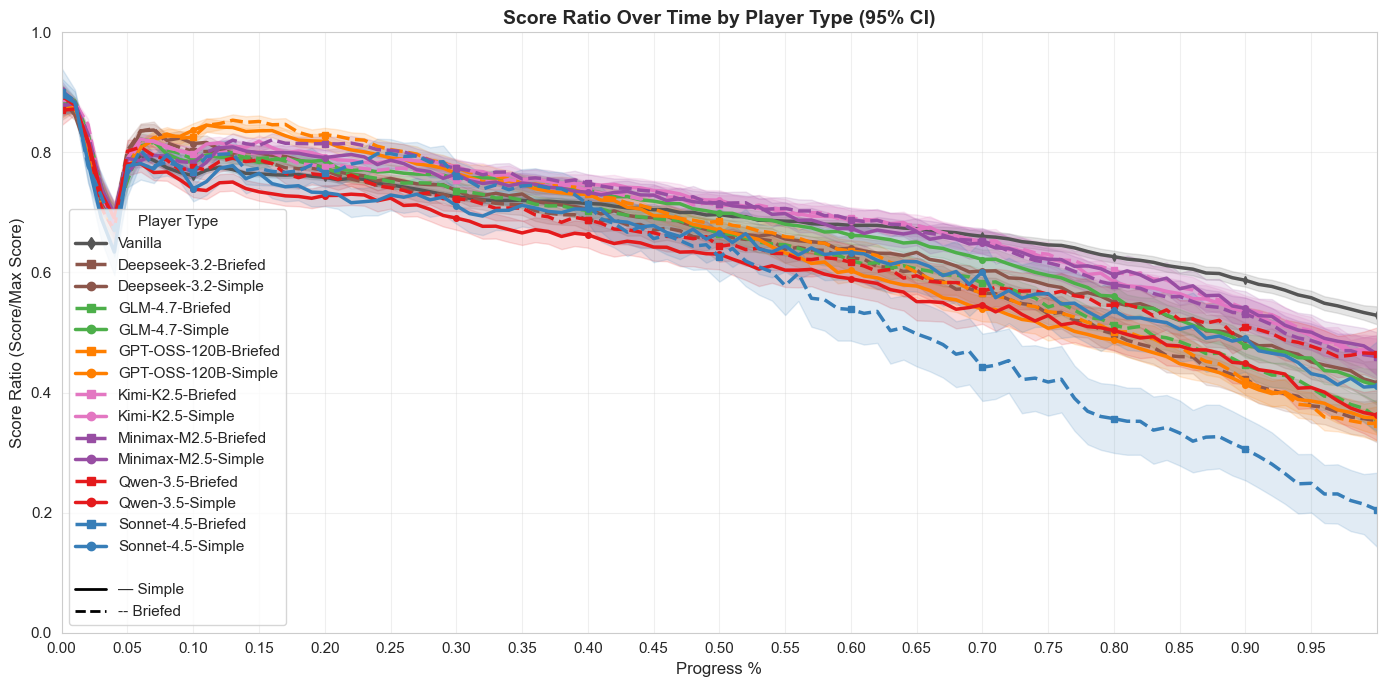

,N,Mean,Std,Min,Max,Slope,r
Vanilla,330664,0.689,0.240,0.0,1.0,-0.232797,-0.281
Deepseek-3.2-Briefed,48321,0.634,0.274,0.0,1.0,-0.455371,-0.482
Deepseek-3.2-Simple,48321,0.660,0.254,0.0,1.0,-0.380580,-0.433
GLM-4.7-Briefed,75725,0.643,0.260,0.0,1.0,-0.428055,-0.476
GLM-4.7-Simple,75725,0.671,0.238,0.0,1.0,-0.379281,-0.461
GPT-OSS-120B-Briefed,65948,0.654,0.272,0.0,1.0,-0.501397,-0.532
GPT-OSS-120B-Simple,65948,0.642,0.268,0.0,1.0,-0.510204,-0.551
Kimi-K2.5-Briefed,71212,0.692,0.250,0.0,1.0,-0.317244,-0.368
Kimi-K2.5-Simple,71212,0.694,0.257,0.0,1.0,-0.337949,-0.380
Minimax-M2.5-Briefed,50190,0.693,0.247,0.0,1.0,-0.347556,-0.406


In [17]:
# Plot score ratio over time using the generalized plot_metric_over_time function
# This calculates score_ratio as score/max_score dynamically
fig, ax = plot_metric_over_time(
    turn_df,
    metric_calculation=lambda df: df['score'] / df['max_score'],
    title="Score Ratio Over Time by Player Type",
    ylabel="Score Ratio (Score/Max Score)",
    figsize=(14, 7),
    show_confidence=True,
    confidence_level=0.95,
    print_summary=True,
    use_turn_progress=True,
    ylim=(0, 1)  # Score ratio is always between 0 and 1
)

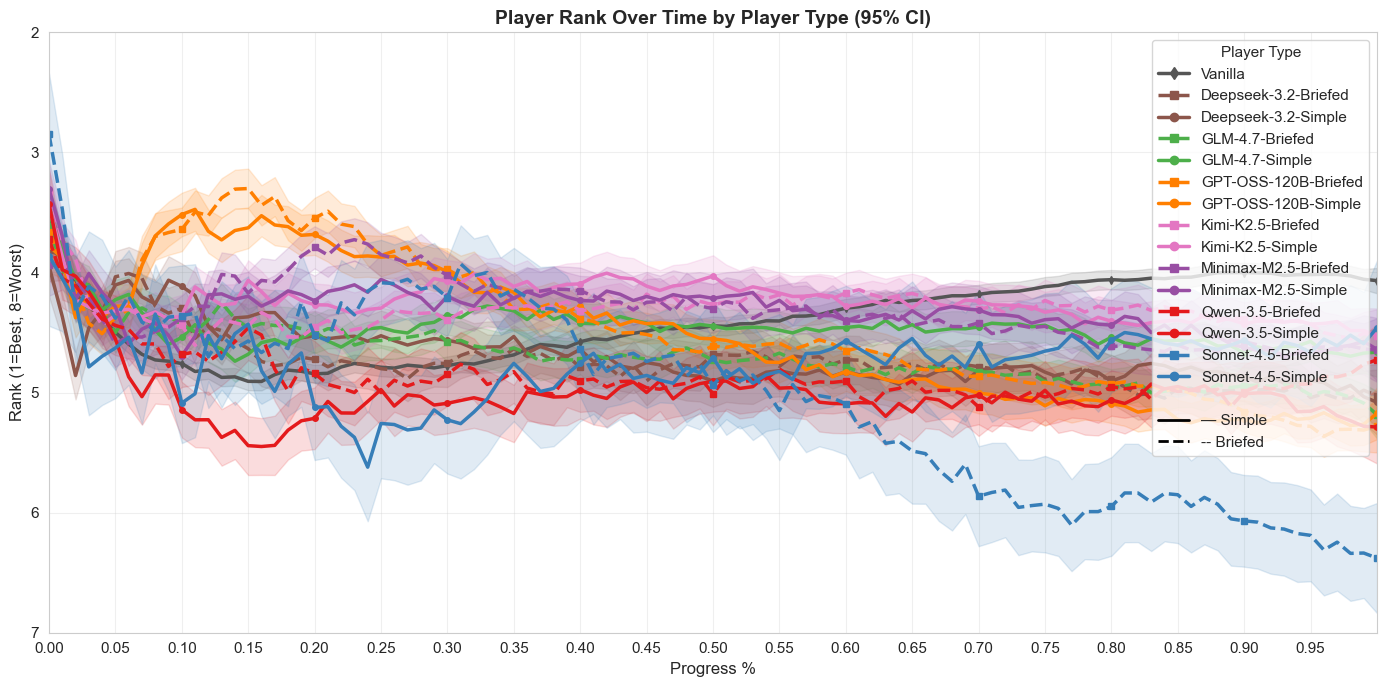

,N,Mean,Std,Min,Max,Slope,r
Vanilla,330664,4.398,2.300,1,8,-0.813318,-0.102
Deepseek-3.2-Briefed,48321,4.734,2.281,1,8,0.650083,0.082
Deepseek-3.2-Simple,48321,4.692,2.327,1,8,0.672310,0.084
GLM-4.7-Briefed,75725,4.698,2.244,1,8,0.770670,0.099
GLM-4.7-Simple,75725,4.469,2.223,1,8,0.266330,0.035
GPT-OSS-120B-Briefed,65948,4.460,2.355,1,8,1.767732,0.217
GPT-OSS-120B-Simple,65948,4.529,2.284,1,8,1.813635,0.229
Kimi-K2.5-Briefed,71212,4.313,2.310,1,8,0.049641,0.006
Kimi-K2.5-Simple,71212,4.240,2.362,1,8,0.267331,0.033
Minimax-M2.5-Briefed,50190,4.314,2.282,1,8,0.646402,0.082


In [18]:
# Create the rank over time plot with 95% confidence intervals
# Using the generalized plot_metric_over_time function
# Note: Lower rank is better (1 = first place, 4 = last place)
# We invert the y-axis to show better performance at the top
fig, ax = plot_metric_over_time(
    turn_df,
    metric_col='rank',  # Use the 'rank' column directly
    title="Player Rank Over Time by Player Type",
    ylabel="Rank (1=Best, 8=Worst)",
    figsize=(14, 7),
    show_confidence=True,
    confidence_level=0.95,
    print_summary=True,
    use_turn_progress=True,
    ylim=(2, 7),   # Set y-axis limits for rank (1-8 with padding)
    invert_y=True,     # Invert y-axis so lower (better) rank appears higher
    legend_loc='upper right'
)

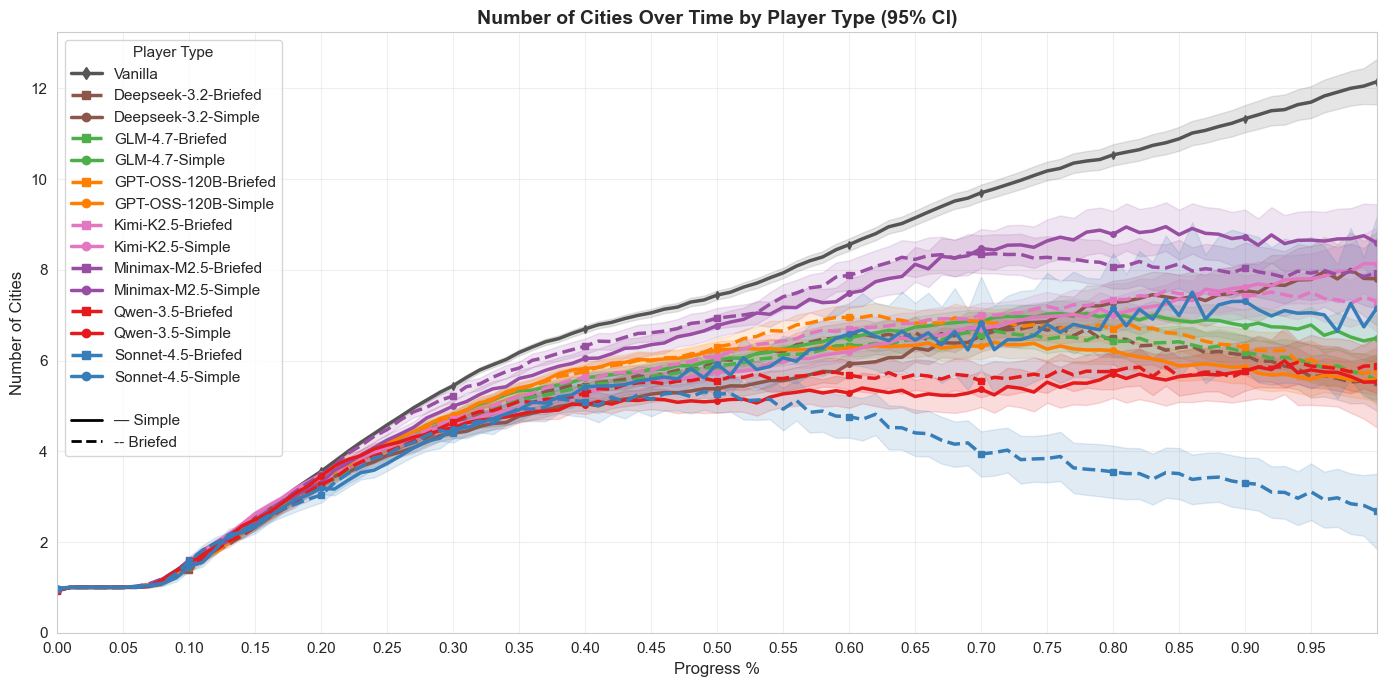

,N,Mean,Std,Min,Max,Slope,r
Vanilla,330664,7.142,6.057,0,72,11.633598,0.555
Deepseek-3.2-Briefed,48321,4.961,3.733,0,25,5.334799,0.414
Deepseek-3.2-Simple,48321,5.130,4.405,0,49,6.928445,0.455
GLM-4.7-Briefed,75725,4.963,3.762,0,41,5.362925,0.412
GLM-4.7-Simple,75725,5.230,3.651,0,31,6.066960,0.481
GPT-OSS-120B-Briefed,65948,5.189,3.790,0,24,5.559438,0.424
GPT-OSS-120B-Simple,65948,4.961,3.471,0,26,4.826880,0.402
Kimi-K2.5-Briefed,71212,5.389,4.078,0,40,6.817612,0.484
Kimi-K2.5-Simple,71212,5.279,4.292,0,58,6.886941,0.464
Minimax-M2.5-Briefed,50190,6.033,4.572,0,36,7.682807,0.486


In [19]:
# Plot number of cities over time using the generalized plot_metric_over_time function
# Cities are a key indicator of expansion and empire building in Civilization
fig, ax = plot_metric_over_time(
    turn_df,
    metric_col='cities',  # Use the 'cities' column directly
    title="Number of Cities Over Time by Player Type",
    ylabel="Number of Cities",
    figsize=(14, 7),
    show_confidence=True,
    confidence_level=0.95,
    use_turn_progress=True,
    print_summary=True,
    ylim=(0, None),    # Start at 0, let max adjust automatically
    legend_loc='upper left'  # Cities generally increase over time
)

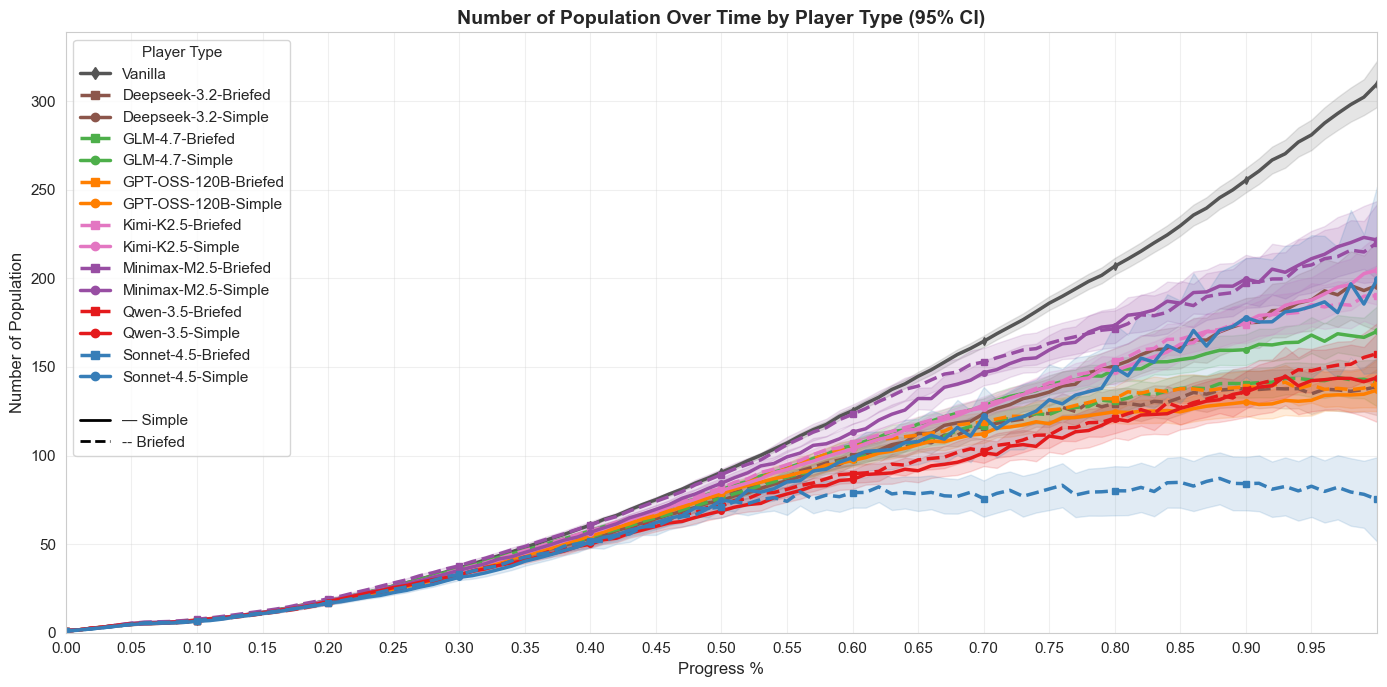

,N,Mean,Std,Min,Max,Slope,r
Vanilla,330664,112.017,142.030,0,2451,312.052438,0.635
Deepseek-3.2-Briefed,48321,73.991,81.231,0,651,166.385369,0.593
Deepseek-3.2-Simple,48321,83.382,103.854,0,1122,210.715346,0.587
GLM-4.7-Briefed,75725,75.087,80.983,0,965,171.218871,0.611
GLM-4.7-Simple,75725,82.960,87.170,0,785,196.175006,0.651
GPT-OSS-120B-Briefed,65948,76.222,81.517,0,764,170.130975,0.603
GPT-OSS-120B-Simple,65948,72.638,74.315,0,603,159.173480,0.619
Kimi-K2.5-Briefed,71212,85.875,96.874,0,898,211.386031,0.631
Kimi-K2.5-Simple,71212,85.373,100.910,0,1322,212.909832,0.611
Minimax-M2.5-Briefed,50190,96.924,111.144,0,943,242.119992,0.630


In [20]:
# Plot number of population over time using the generalized plot_metric_over_time function
# Cities are a key indicator of expansion and empire building in Civilization
fig, ax = plot_metric_over_time(
    turn_df,
    metric_col='population',  # Use the 'population' column directly
    title="Number of Population Over Time by Player Type",
    ylabel="Number of Population",
    figsize=(14, 7),
    show_confidence=True,
    confidence_level=0.95,
    use_turn_progress=True,
    print_summary=True,
    ylim=(0, None),    # Start at 0, let max adjust automatically
    legend_loc='upper left'  # Population generally increase over time
)

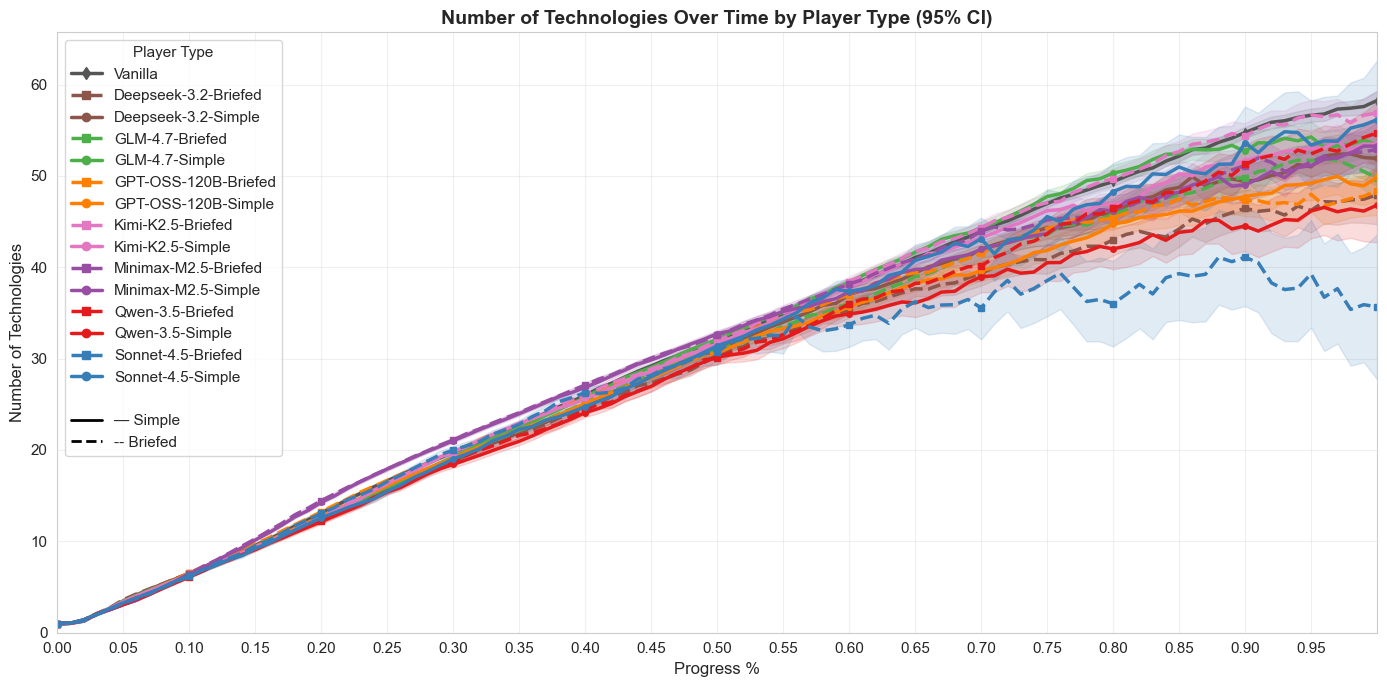

,N,Mean,Std,Min,Max,Slope,r
Vanilla,330664,31.358,19.918,0,82,59.820392,0.868
Deepseek-3.2-Briefed,48321,28.040,19.561,0,82,49.266912,0.729
Deepseek-3.2-Simple,48321,29.507,19.449,0,82,54.781596,0.815
GLM-4.7-Briefed,75725,29.484,19.841,0,82,54.081676,0.788
GLM-4.7-Simple,75725,31.098,19.979,0,82,58.789723,0.851
GPT-OSS-120B-Briefed,65948,29.450,19.253,0,82,51.180860,0.768
GPT-OSS-120B-Simple,65948,28.841,19.320,0,82,51.358602,0.768
Kimi-K2.5-Briefed,71212,31.313,20.362,0,82,59.997754,0.853
Kimi-K2.5-Simple,71212,30.378,20.036,0,82,56.459061,0.815
Minimax-M2.5-Briefed,50190,30.705,19.211,0,82,54.185145,0.816


In [21]:
# Plot number of technologies over time using the generalized plot_metric_over_time function
fig, ax = plot_metric_over_time(
    turn_df,
    metric_col='technologies',  # Use the 'technologies' column directly
    title="Number of Technologies Over Time by Player Type",
    ylabel="Number of Technologies",
    figsize=(14, 7),
    show_confidence=True,
    confidence_level=0.95,
    print_summary=True,
    use_turn_progress=True,
    ylim=(0, None),    # Start at 0, let max adjust automatically
    legend_loc='upper left'  # Technology generally increase over time
)

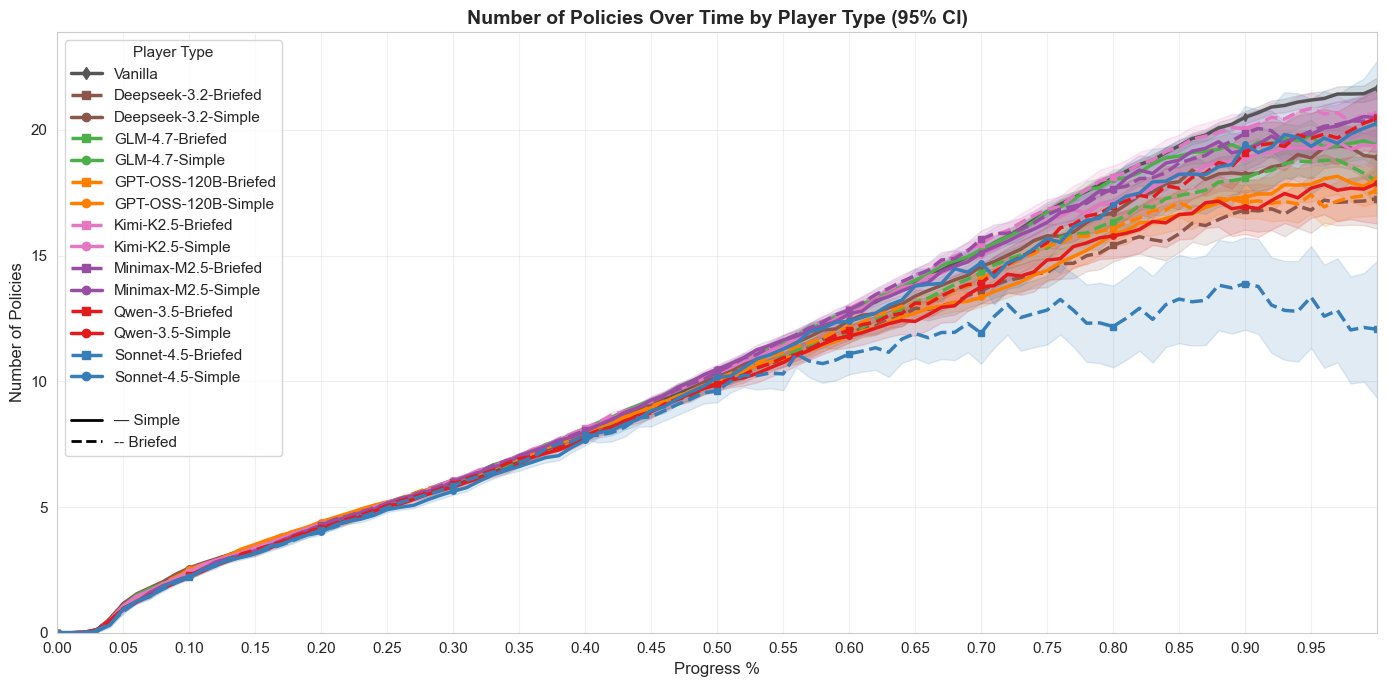

,N,Mean,Std,Min,Max,Slope,r
Vanilla,330664,10.806,7.710,0,36,22.763843,0.854
Deepseek-3.2-Briefed,48321,9.643,7.226,0,33,18.032845,0.722
Deepseek-3.2-Simple,48321,10.292,7.323,0,34,20.251612,0.800
GLM-4.7-Briefed,75725,10.081,7.333,0,33,19.847342,0.783
GLM-4.7-Simple,75725,10.670,7.411,0,35,21.508729,0.839
GPT-OSS-120B-Briefed,65948,9.957,7.144,0,38,18.782281,0.759
GPT-OSS-120B-Simple,65948,9.848,7.051,0,35,18.701940,0.766
Kimi-K2.5-Briefed,71212,10.818,7.765,0,36,22.370336,0.834
Kimi-K2.5-Simple,71212,10.470,7.511,0,35,20.887791,0.805
Minimax-M2.5-Briefed,50190,10.665,7.858,0,38,21.837252,0.804


In [22]:
# Plot number of policies over time using the generalized plot_metric_over_time function
fig, ax = plot_metric_over_time(
    turn_df,
    metric_col='policies',  # Use the 'policies' column directly
    title="Number of Policies Over Time by Player Type",
    ylabel="Number of Policies",
    figsize=(14, 7),
    show_confidence=True,
    confidence_level=0.95,
    print_summary=True,
    use_turn_progress=True,
    ylim=(0, None),    # Start at 0, let max adjust automatically
    legend_loc='upper left'  # Technology generally increase over time
)